## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00262ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ====================================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_linattn 4cd34300/last.pt'... done; this took 0.056s.
01:   Model is ready. Current epoch to train is 13.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_linattn 4cd34300/.
00: Launching 'AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 128 for valuation. The model has 40497 parameters. Resuming from epoch 13.
00: Training 'train_s

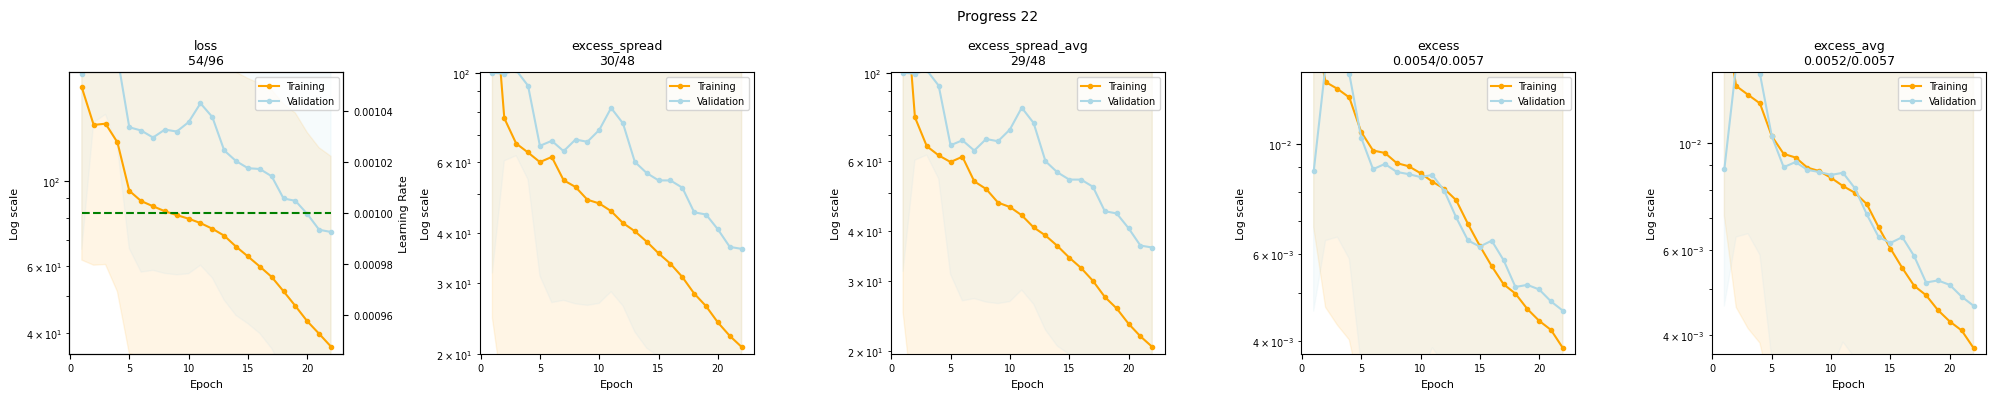

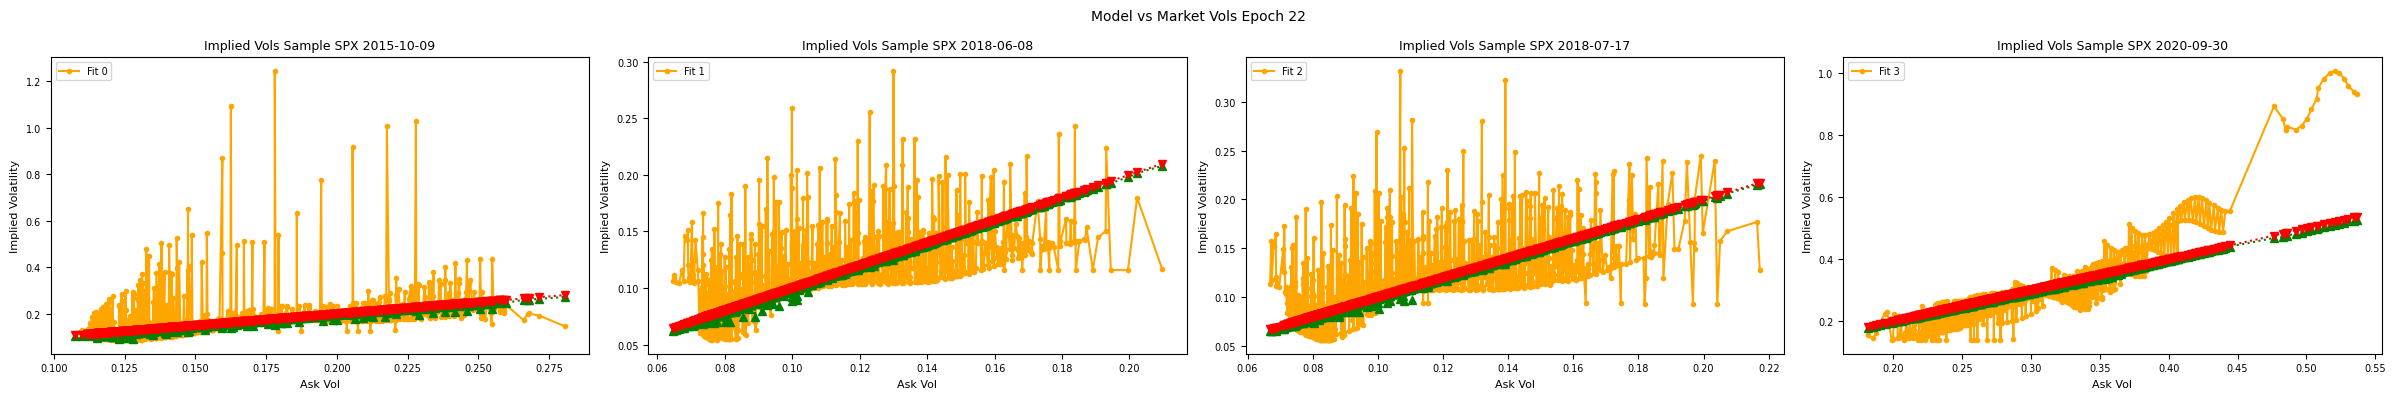

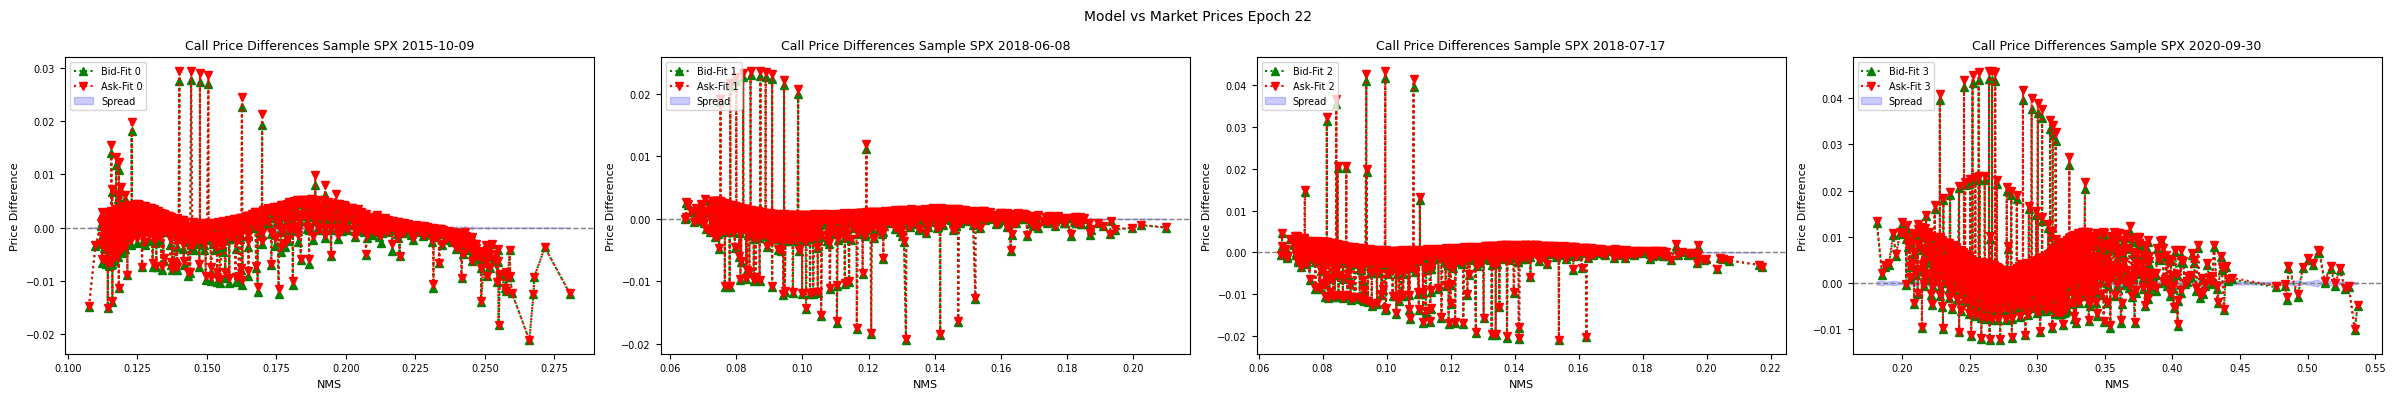

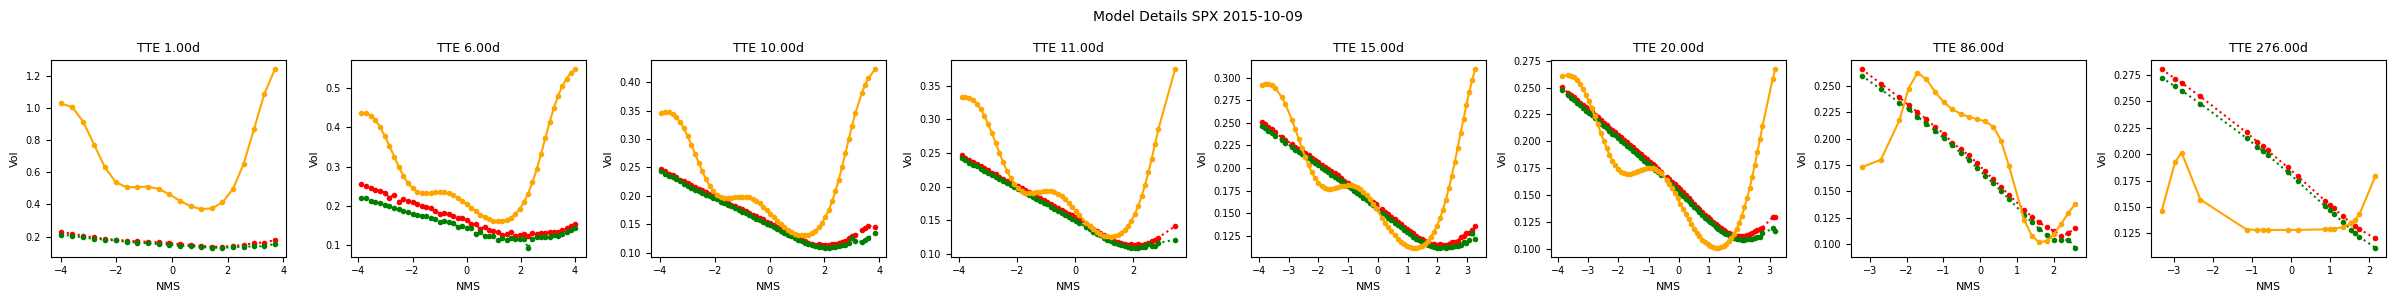

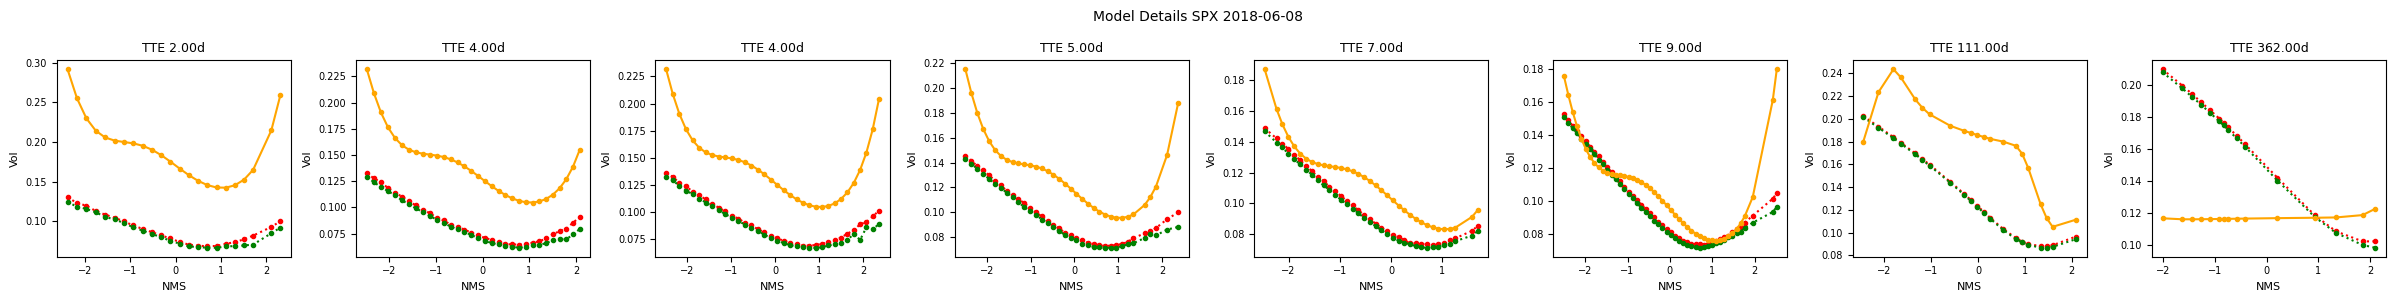

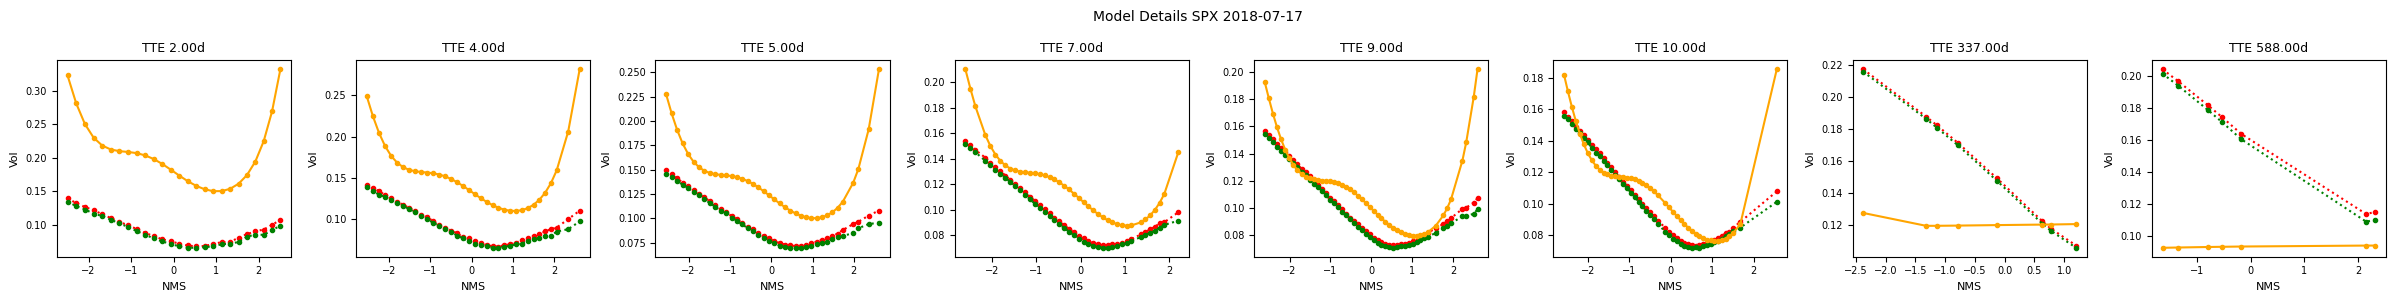

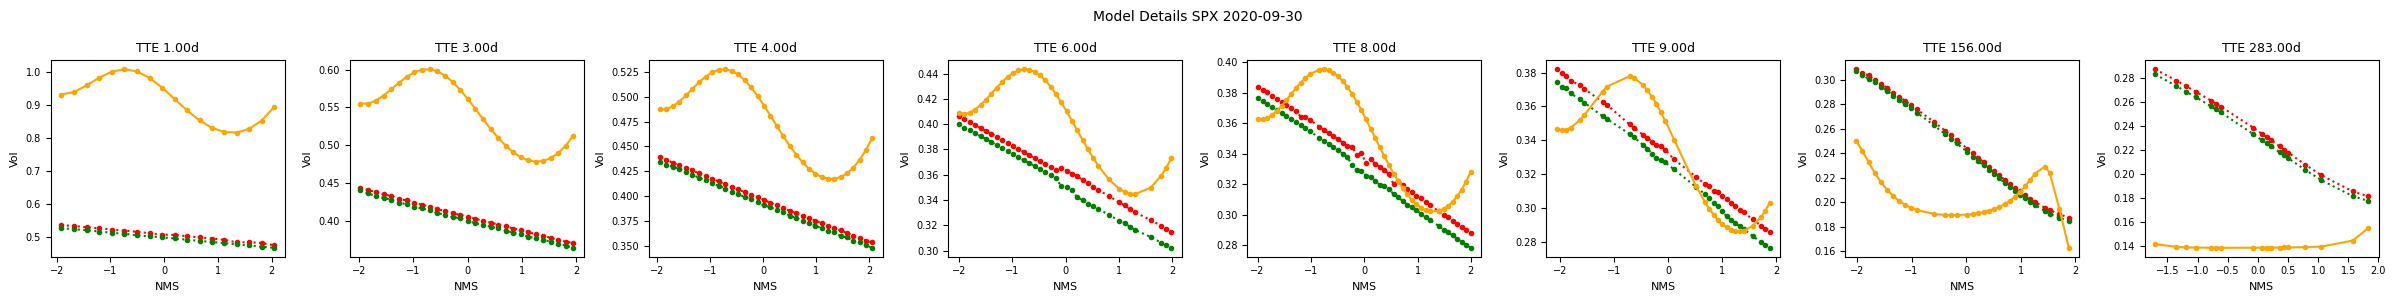

00: Training 'train_sqrtVar_vol_linattn' epoch 15/1000 error avg trn 66.11; val 63.47/107.9 [16s 2s 0.63s]. LR: 1.00e-03, GN 2.491, excess_weighted: 2.454e-13/1.938e-13, excess_weighted_avg: 0.005051/0.005423, excess_spread: 35.55/53.99, excess_spread_avg: 34.41/53.99, excess: 0.00623/0.006213, excess_avg: 0.006048/0.006213. ETA: 11:26:31.
00: Training 'train_sqrtVar_vol_linattn' epoch 16/1000 error avg trn 61.84; val 59.74/107.4 [16s 2s 0.63s]. LR: 1.00e-03, GN 2.95, excess_weighted: 2.31e-13/1.938e-13, excess_weighted_avg: 0.00473/0.005371, excess_spread: 33.48/53.97, excess_spread_avg: 32.4/53.97, excess: 0.005671/0.006385, excess_avg: 0.005511/0.006385. ETA: 17:14:43.
00: Training 'train_sqrtVar_vol_linattn' epoch 17/1000 error avg trn 57.63; val 56.11/102.8 [16s 2s 0.63s]. LR: 1.00e-03, GN 3.406, excess_weighted: 2.144e-13/1.859e-13, excess_weighted_avg: 0.00443/0.005128, excess_spread: 31.04/51.79, excess_spread_avg: 30.08/51.79, excess: 0.005212/0.005832, excess_avg: 0.005064/0.

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = AttentionEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 0,  # linear
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 10, debug=False, val_batch_size=128 )
